In [50]:
#  LIBRARIES IMPORT

import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline 

In [51]:
# 1. Load Datasets     
df=pd.read_csv('Unemployment in India.csv')
df_11_2020=pd.read_csv('Unemployment_Rate_upto_11_2020.csv')

In [52]:
# Data inspection
df.head(20)

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural
5,Andhra Pradesh,31-10-2019,Monthly,3.52,12017412.0,43.01,Rural
6,Andhra Pradesh,30-11-2019,Monthly,4.12,11397681.0,41.00,Rural
7,Andhra Pradesh,31-12-2019,Monthly,4.38,12528395.0,45.14,Rural
8,Andhra Pradesh,31-01-2020,Monthly,4.84,12016676.0,43.46,Rural
9,Andhra Pradesh,29-02-2020,Monthly,5.91,11723617.0,42.83,Rural


In [53]:
df_11_2020.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74


In [54]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 42.1 KB


In [55]:
df_11_2020.info()

<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 9 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    267 non-null    str    
 1    Date                                     267 non-null    str    
 2    Frequency                                267 non-null    str    
 3    Estimated Unemployment Rate (%)          267 non-null    float64
 4    Estimated Employed                       267 non-null    int64  
 5    Estimated Labour Participation Rate (%)  267 non-null    float64
 6   Region.1                                  267 non-null    str    
 7   longitude                                 267 non-null    float64
 8   latitude                                  267 non-null    float64
dtypes: float64(4), int64(1), str(4)
memory usage: 18.9 KB


In [56]:
df.shape

(768, 7)

In [57]:
df_11_2020.shape

(267, 9)

In [58]:
df.describe()

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [59]:
# 2. Data Cleaning (Handle Missing & Duplicate Values)
df.isnull().sum()

Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

In [60]:
df_11_2020.isnull().sum()

Region                                      0
 Date                                       0
 Frequency                                  0
 Estimated Unemployment Rate (%)            0
 Estimated Employed                         0
 Estimated Labour Participation Rate (%)    0
Region.1                                    0
longitude                                   0
latitude                                    0
dtype: int64

In [61]:
df=df.dropna()

In [62]:
df.isna().sum()

Region                                      0
 Date                                       0
 Frequency                                  0
 Estimated Unemployment Rate (%)            0
 Estimated Employed                         0
 Estimated Labour Participation Rate (%)    0
Area                                        0
dtype: int64

In [63]:
df.shape 

(740, 7)

In [64]:
df.duplicated().sum()

0

In [65]:
df_11_2020.duplicated().sum()

0

In [66]:
# Rename columns for clarity
df.columns=['State','Date','Frequency','Estimated Unemployment Rate','Estimated Employed','Estimated Labour Participation Rate','Area']

In [67]:
# Rename columns for clarity
df_11_2020.columns=['State','Date','Frequency','Estimated Unemployment Rate','Estimated Employed','Estimated Labour Participation Rate','Region','longitude','latitude']

In [68]:
df.columns

Index(['State', 'Date', 'Frequency', 'Estimated Unemployment Rate',
       'Estimated Employed', 'Estimated Labour Participation Rate', 'Area'],
      dtype='str')

In [69]:
df_11_2020.columns

Index(['State', 'Date', 'Frequency', 'Estimated Unemployment Rate',
       'Estimated Employed', 'Estimated Labour Participation Rate', 'Region',
       'longitude', 'latitude'],
      dtype='str')

In [70]:
# State level frequency checks
df['State'].value_counts().idxmax()

'Andhra Pradesh'

In [71]:
df['State'].value_counts()

State
Andhra Pradesh      28
Bihar               28
Chhattisgarh        28
Delhi               28
Gujarat             28
Haryana             28
Himachal Pradesh    28
Jharkhand           28
Karnataka           28
Kerala              28
Madhya Pradesh      28
Maharashtra         28
Odisha              28
Punjab              28
Rajasthan           28
Tamil Nadu          28
Telangana           28
Tripura             28
Uttar Pradesh       28
West Bengal         28
Meghalaya           27
Uttarakhand         27
Assam               26
Puducherry          26
Goa                 24
Jammu & Kashmir     21
Sikkim              17
Chandigarh          12
Name: count, dtype: int64

In [72]:
# State level frequency checks
df['State'].value_counts().idxmin()

'Chandigarh'

In [73]:
# State level frequency checks
df_11_2020['State'].value_counts().idxmax()

'Andhra Pradesh'

In [74]:
# State level frequency checks
df_11_2020['State'].value_counts().idxmin()

'Sikkim'

In [75]:
import datetime as dt 
import calendar

# 3. Date Formatting & Extracting Month

df['Date']=pd.to_datetime(df['Date'],dayfirst=True )
df['month_int']=df['Date'].dt.month
df['month']=df['month_int'].apply(lambda x: calendar.month_abbr[x])

In [76]:
df_11_2020['Date']=pd.to_datetime(df_11_2020['Date'],dayfirst=True )
df_11_2020['month_int']=df_11_2020['Date'].dt.month
df_11_2020['month']=df_11_2020['month_int'].apply(lambda x: calendar.month_abbr[x])

In [77]:
# Check highest/lowest unemployment months
df['month'].value_counts().idxmax()

'May'

In [78]:
# Check highest/lowest unemployment months
df_11_2020['month'].value_counts().idxmax()

'Mar'

In [79]:
# Check highest/lowest unemployment months
df['month'].value_counts().idxmin()

'Apr'

In [80]:
# Check highest/lowest unemployment months
df_11_2020['month'].value_counts().idxmin()

'Jan'

In [81]:
df.head(3)

,State,Date,Frequency,Estimated Unemployment Rate,Estimated Employed,Estimated Labour Participation Rate,Area,month_int,month
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,5,May
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural,6,Jun
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural,7,Jul


In [82]:
df_11_2020.head(3)

,State,Date,Frequency,Estimated Unemployment Rate,Estimated Employed,Estimated Labour Participation Rate,Region,longitude,latitude,month_int,month
0,Andhra Pradesh,2020-01-31,M,5.48,16635535,41.02,South,15.9129,79.74,1,Jan
1,Andhra Pradesh,2020-02-29,M,5.83,16545652,40.90,South,15.9129,79.74,2,Feb
2,Andhra Pradesh,2020-03-31,M,5.79,15881197,39.18,South,15.9129,79.74,3,Mar


In [83]:
# Drop unnecessary columns
df.drop(columns=['Frequency','month_int'],inplace=True)

In [84]:
df_11_2020.drop(columns=['Frequency','month_int'],inplace=True)

In [85]:
# 4. Top 10 States with Highest Unemployment
df1=df[['State','Estimated Unemployment Rate']].groupby('State').mean().sort_values('Estimated Unemployment Rate',ascending=False)

In [86]:
df1_11_2020=df_11_2020[['State','Estimated Unemployment Rate']].groupby('State').mean().sort_values('Estimated Unemployment Rate',ascending=False)

In [87]:
df1.head()

,Estimated Unemployment Rate
State,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357


In [88]:
df1_11_2020.head()

,Estimated Unemployment Rate
State,
Haryana,27.477
Tripura,25.055
Jharkhand,19.539
Bihar,19.471
Delhi,18.414


Text(0, 0.5, 'Number of people unemployment %')

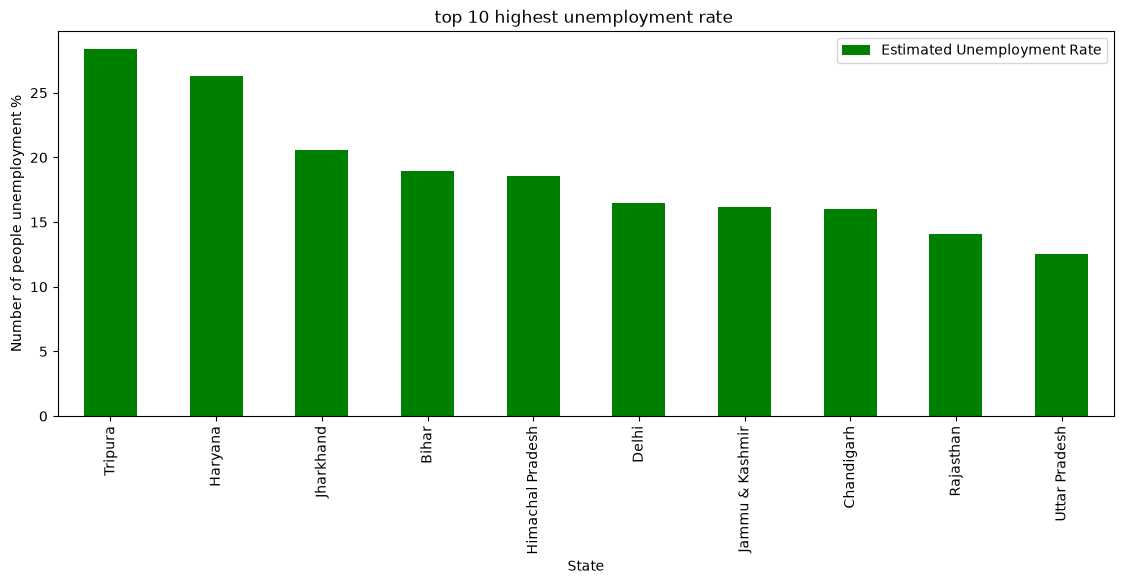

In [89]:
fig=plt.figure(figsize=(30,5))
ax0=fig.add_subplot(1,2,1)
df1[:10].plot(kind='bar',color='green',ax=ax0)
ax0.set_title('top 10 highest unemployment rate ')
ax0.set_xlabel('State')
ax0.set_ylabel('Number of people unemployment %')


Text(0, 0.5, 'Number of people unemployment %')

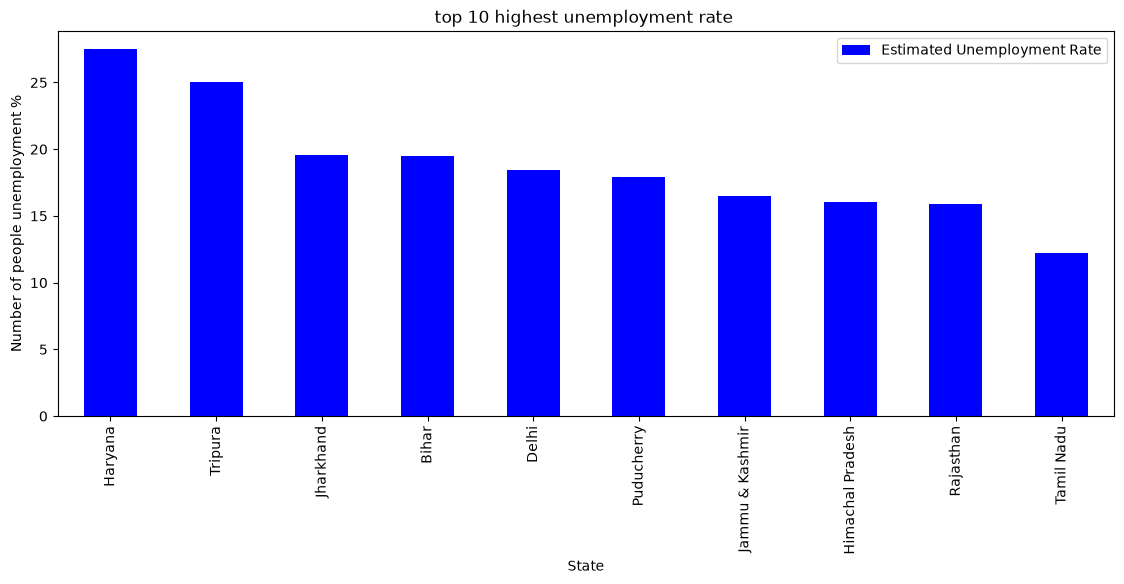

In [90]:
fig=plt.figure(figsize=(30,5))
ax0=fig.add_subplot(1,2,1)
df1_11_2020[:10].plot(kind='bar',color='blue',ax=ax0)
ax0.set_title('top 10 highest unemployment rate ')
ax0.set_xlabel('State')
ax0.set_ylabel('Number of people unemployment %')


### 📊 Key Takeaway: Top 10 States
* Regional Spike: Unemployment is highest in states like Haryana and Tripura due to localized economic disruptions.
* Steep Gap: A sharp difference exists between the top 3 states and the rest of the list.

In [91]:
# 5. Monthly Unemployment Trends
df2=df[['month','Estimated Unemployment Rate']].groupby('month').mean().sort_values('Estimated Unemployment Rate',ascending=False)
df2.head(10)

,Estimated Unemployment Rate
month,
Apr,23.641569
May,16.646190
Mar,10.700577
Jun,10.553462
Feb,9.964717
Jan,9.950755
Oct,9.900909
Nov,9.868364
Aug,9.637925


In [92]:

df2_11_2020=df_11_2020[['month','Estimated Unemployment Rate']].groupby('month').mean().sort_values('Estimated Unemployment Rate',ascending=False)
df2_11_2020.head(10)

,Estimated Unemployment Rate
month,
May,23.244444
Apr,22.236154
Jun,10.911111
Mar,10.782593
Aug,10.313333
Jul,9.834444
Feb,9.266154
Jan,9.196538
Sep,8.705926


Text(0, 0.5, 'Number of people unemployment %')

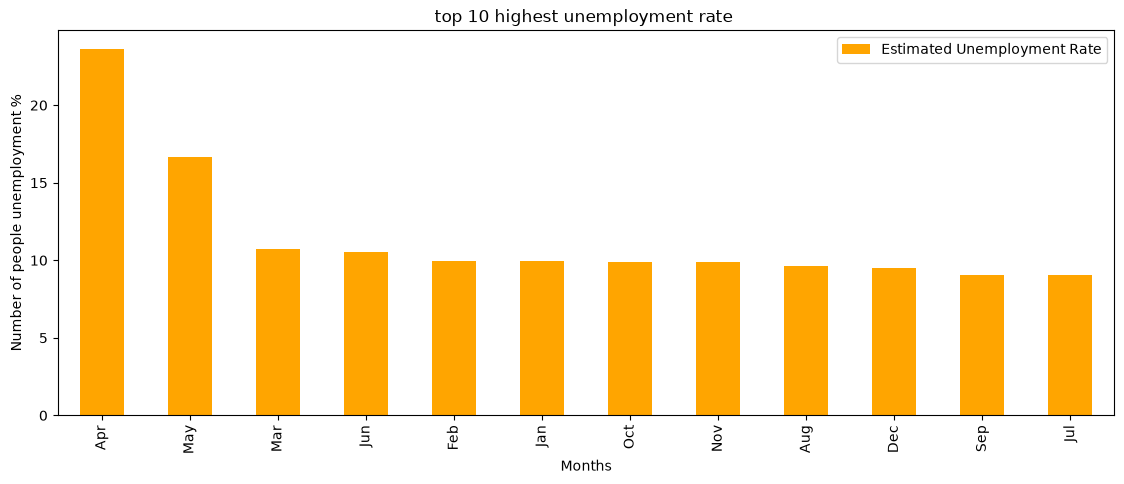

In [93]:
fig=plt.figure(figsize=(30,5))
ax0=fig.add_subplot(1,2,1)
df2[:12].plot(kind='bar',color='orange',ax=ax0)
ax0.set_title('top 10 highest unemployment rate ')
ax0.set_xlabel('Months')
ax0.set_ylabel('Number of people unemployment %')


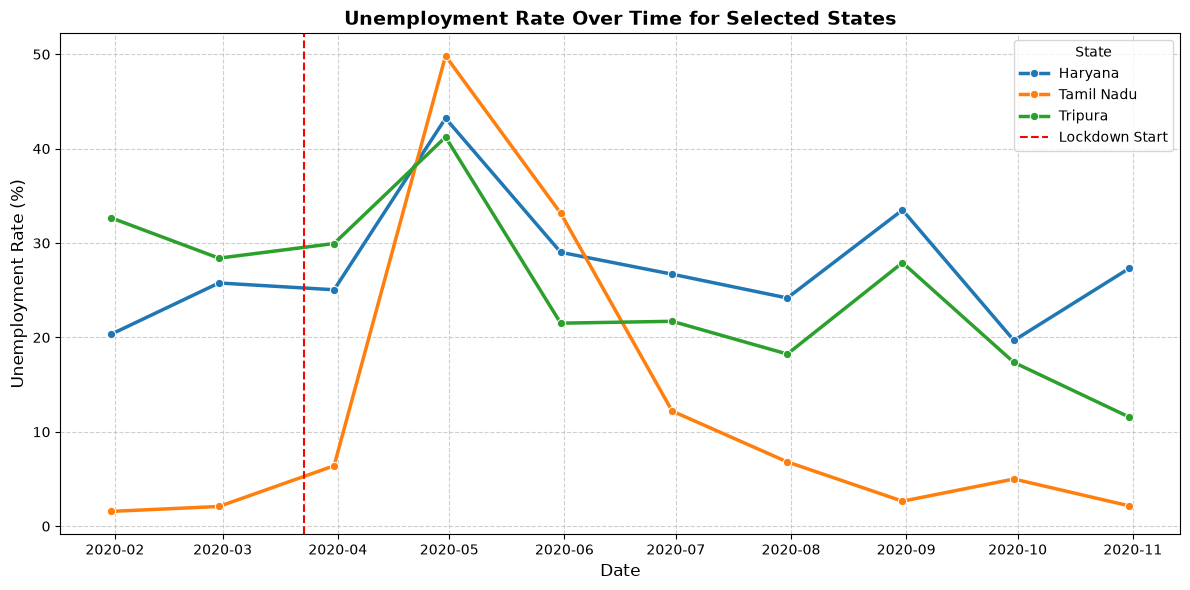

In [94]:
selected_states = ['Haryana', 'Tripura', 'Tamil Nadu']
df_filtered = df_11_2020[df_11_2020['State'].isin(selected_states)]

plt.figure(figsize=(12, 6))
sns.lineplot(data=df_filtered, x='Date', y='Estimated Unemployment Rate', hue='State',marker='o',linewidth=2.5)

plt.title('Unemployment Rate Over Time for Selected States', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Unemployment Rate (%)', fontsize=12)
plt.axvline(pd.to_datetime('2020-03-23'), color='red', linestyle='--', label='Lockdown Start')
plt.legend(title='State')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

Text(0, 0.5, 'Number of people unemployment %')

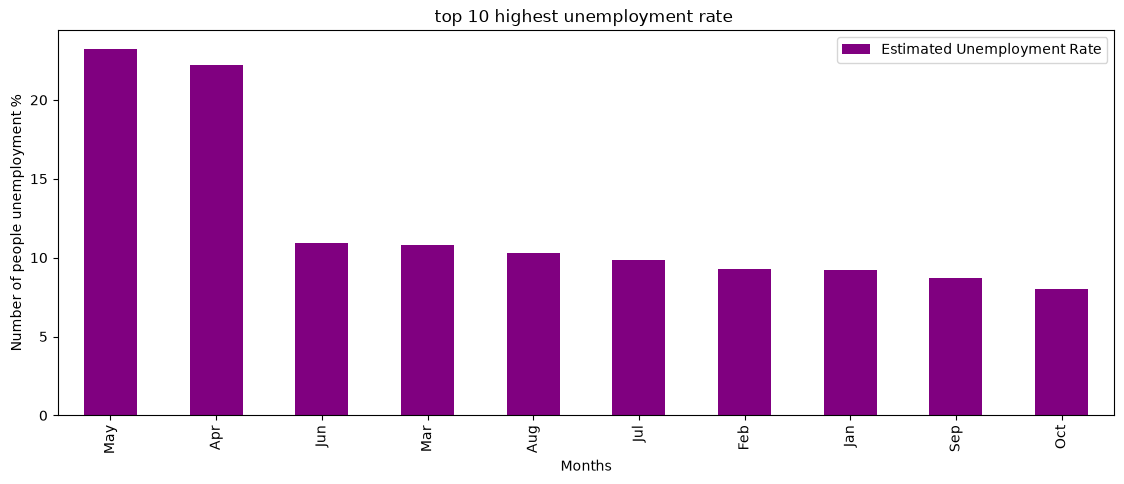

In [95]:
fig=plt.figure(figsize=(30,5))
ax0=fig.add_subplot(1,2,1)
df2_11_2020[:12].plot(kind='bar',color='purple',ax=ax0)
ax0.set_title('top 10 highest unemployment rate ')
ax0.set_xlabel('Months')
ax0.set_ylabel('Number of people unemployment %')




### 📊 Key Takeaway: Monthly Trends
* Lockdown Impact: April–May 2020 saw the highest spike in unemployment due to nationwide COVID-19 lockdowns.
* Gradual Recovery: Rates steadily declined in later months as restrictions eased.



Text(0.5, 1.0, 'Correlation Heatmap - df')

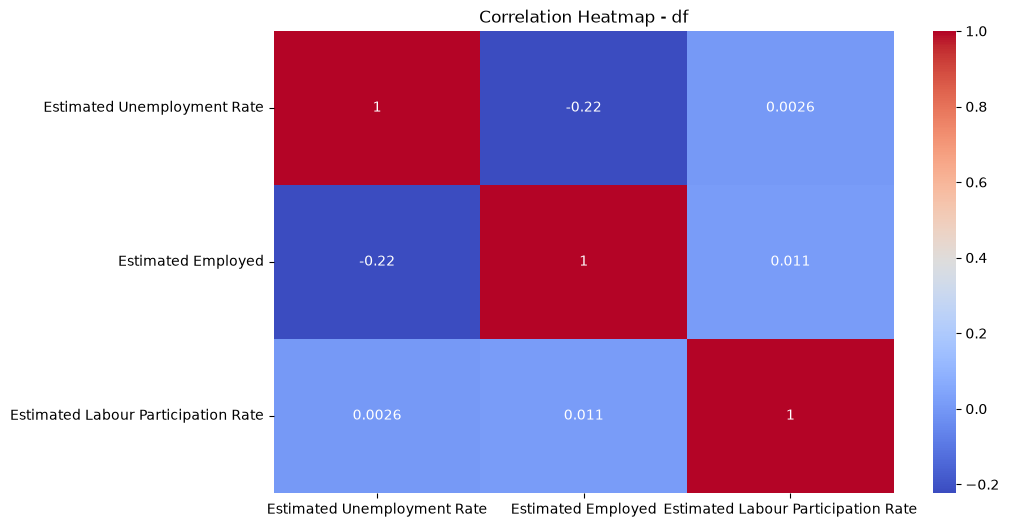

In [96]:
# 6. Correlation Heatmaps

fig=plt.figure(figsize=(10,6))
ax0=fig.add_subplot(1,1,1)
sns.heatmap(df[['Estimated Unemployment Rate','Estimated Employed','Estimated Labour Participation Rate']].corr(), annot=True, cmap='coolwarm', ax=ax0)
ax0.set_title('Correlation Heatmap - df')

Text(0.5, 1.0, 'Correlation Heatmap - df_11_2020')

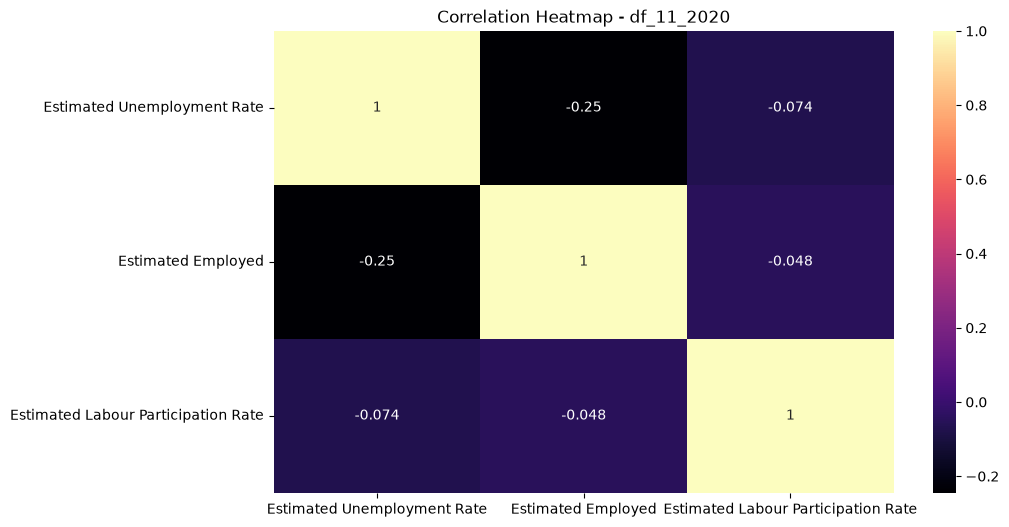

In [97]:
fig=plt.figure(figsize=(10,6))
ax0=fig.add_subplot(1,1,1)
sns.heatmap(df_11_2020[['Estimated Unemployment Rate','Estimated Employed','Estimated Labour Participation Rate']].corr(), annot=True, cmap='magma', ax=ax0)
ax0.set_title('Correlation Heatmap - df_11_2020')

### 📊 Key Takeaway: Correlations
* Inverse Relation: Unemployment Rate and Employed show a strong negative correlation, as expected.
* Stable Workforce: Labour Participation Rate remained relatively steady despite employment swings

Pre-COVID Mean Labour Participation Rate: 44.40%
Post-COVID Mean Labour Participation Rate: 41.02%


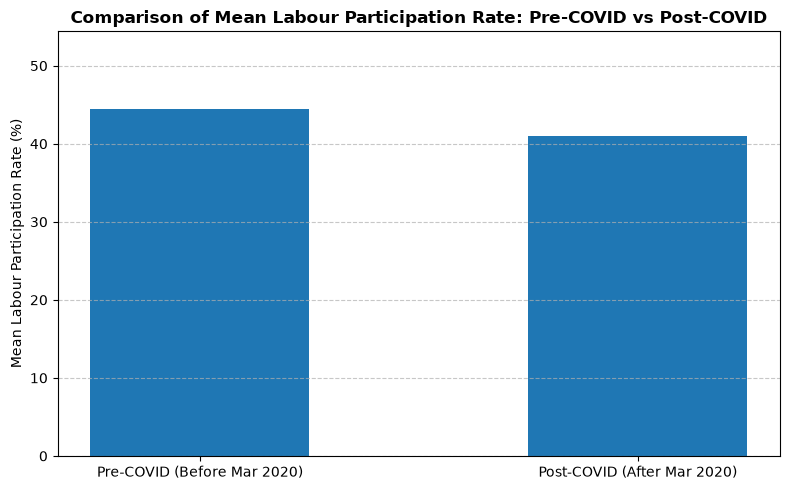

In [98]:
# 7. Pre-COVID vs Post-COVID Mean Comparison

# 1. Define cutoff date (March 2020 - Lockdown start)
cutoff_date = '2020-03-23'

# 2. Split Data into Pre-COVID and Post-COVID
pre_covid = df_11_2020[df_11_2020['Date'] < cutoff_date]
post_covid = df_11_2020[df_11_2020['Date'] >= cutoff_date]

# 3. Calculate Mean Rates
pre_mean = pre_covid['Estimated Labour Participation Rate'].mean()
post_mean = post_covid['Estimated Labour Participation Rate'].mean()

print(f"Pre-COVID Mean Labour Participation Rate: {pre_mean:.2f}%")
print(f"Post-COVID Mean Labour Participation Rate: {post_mean:.2f}%")

# 4. Bar Graph Plotting
plt.figure(figsize=(8, 5))
categories = ['Pre-COVID (Before Mar 2020)', 'Post-COVID (After Mar 2020)']
means = [pre_mean, post_mean]

bars = plt.bar(categories, means,width=0.5)


plt.title('Comparison of Mean Labour Participation Rate: Pre-COVID vs Post-COVID', fontsize=12, fontweight='bold')
plt.ylabel('Mean Labour Participation Rate (%)', fontsize=10)
plt.ylim(0, max(means) + 10) # spacing on top
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### 📊 Key Takeaway: Pre vs. Post COVID
* Rate Drop: Average Labour Participation Rate dropped noticeably after March 2020.
* Pandemic Shock: Movement restrictions and closures forced people out of the active workforce.